# exfildns — méthodologie d'apprentissage

Détection par machine learning des requêtes DNS servant à **exfiltrer des données** (DNS tunneling).

**Problématique.** Le DNS est presque toujours autorisé en sortie d'un réseau : un attaquant peut y
cacher des données en les encodant dans des noms de domaine
(`<morceau>.<données encodées>.domaine-attaquant.com`) que le résolveur relaie jusqu'à son serveur.
Peut-on reconnaître ces requêtes **une par une**, à partir du seul nom demandé, pour les détecter
en direct sur un réseau ?

Ce notebook déroule la méthode : données, features, découpage, puis apprentissage et performances.
Il **importe** le paquet `exfildns` au lieu de recopier son code : les fonctions montrées ici sont
exactement celles de l'application déployée.

> Dataset : **CIC-Bell-DNS-EXF-2021** (Canadian Institute for Cybersecurity).
> Mahdavifar, S., et al. *Lightweight Hybrid Detection of Data Exfiltration using DNS based on
> Machine Learning*. ICCNS 2021.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from exfildns.dataset import IP_ATTAQUANT, load_dataset
from exfildns.features import FEATURES, LONGUEUR_MAX, extract_features
from exfildns.model import CAPTURES_TEST, split_par_capture

pd.set_option("display.max_colwidth", 70)
plt.rcParams["figure.dpi"] = 90
DONNEES = "../data"  # dossier contenant Attacks/ et Benign/ (non versionné)

## 1. Le dataset

Le dataset fournit des CSV de features (« light ») et des captures réseau PCAP (« heavy »).
**Les CSV light ne contiennent pas d'exfiltration visible** : 99,94 % des lignes d'attaque sont
identiques à des lignes bénignes, ce n'est que le trafic de fond du poste
(détails dans `docs/donnees.md`). Un modèle entraîné dessus apprendrait un artefact.

On utilise donc les **9 PCAP heavy** (6 captures pendant une exfiltration, une par type de fichier
volé : audio, compressé, exécutable, image, texte, vidéo ; 3 captures de trafic normal), et on
calcule **nos propres features**, avec le même code que l'application.

**Étiquetage par requête** (et non par fichier) :
- `1` (exfiltration) : requête d'une capture d'attaque envoyée au serveur DNS de l'attaquant ;
- `0` (bénin) : requêtes des captures bénignes, et trafic de fond des captures d'attaque
  (envoyé à `8.8.8.8`).

In [2]:
df = load_dataset(DONNEES)  # ~1 min 30 la première fois, puis cache data/requetes.csv
print(f"{len(df)} requêtes, serveur de l'attaquant : {IP_ATTAQUANT}")
df.head()

290196 requêtes, serveur de l'attaquant : 192.168.20.72


,capture,dst,qname,label,FQDN_count,upper,lower,numeric,special,entropy,labels,labels_max,labels_average
0,heavy_audio,192.168.20.72,init.KNUGC2CNMFTWQ43POVSC43LQGN6DGOBQGY3Q,1,40,28,4,7,1,4.496439,2,35,19.5
1,heavy_audio,192.168.20.72,0.J4HgHlgzQH6j0ZYg822fnjet1rH6nhslzKFceUM,1,40,11,19,9,1,4.603056,2,38,19.5
2,heavy_audio,192.168.20.72,1.LnheqmgMMsjhGvJKHSCpGOG1P3b4l7zK1AkVq5N,1,40,16,16,7,1,4.884184,2,38,19.5
3,heavy_audio,192.168.20.72,2.VpHScRdmpxgPHhmb_o5PfNzxgn1rOB1OYfh1NQ5,1,40,14,19,5,2,4.703056,2,38,19.5
4,heavy_audio,192.168.20.72,3.eVnWrTk3RqyHuMo-Lv8QiPUHzf3ZE6sor-1eaNx,1,40,14,17,6,3,4.953056,2,38,19.5


In [3]:
par_capture = df.pivot_table(
    index="capture", columns="label", values="qname", aggfunc="count", fill_value=0
).rename(columns={0: "bénignes", 1: "exfiltration"})
par_capture

label,bénignes,exfiltration
capture,,
benign_heavy_1,23127,0
benign_heavy_2,18187,0
benign_heavy_3,25235,0
heavy_audio,103,38068
heavy_compressed,104,30568
heavy_exe,118,40539
heavy_image,94,41987
heavy_text,235,26907
heavy_video,144,44780


Chaque capture d'attaque contient aussi un peu de trafic normal (étiqueté 0) : le modèle ne peut
donc pas se contenter de reconnaître « la capture » d'où vient une requête.

Exemples de noms de chaque classe :

In [4]:
exemples = pd.concat(
    [
        df[df["label"] == 0].sample(5, random_state=0),
        df[df["label"] == 1].sample(5, random_state=0),
    ]
)
exemples[["capture", "dst", "qname", "label"]]

,capture,dst,qname,label
266634,benign_heavy_3,8.8.8.8,botrygg.se,0
235404,benign_heavy_1,8.8.8.8,my157p.com,0
276844,benign_heavy_3,8.8.8.8,gobento.no,0
227957,benign_heavy_1,8.8.8.8,suzuki.cz,0
257660,benign_heavy_2,8.8.8.8,factoring.ltd,0
83708,heavy_exe,192.168.20.72,14838.h1_jHo1xTi3REyGmaNGeiEJsBcZ-XmhaCZj,1
204409,heavy_video,192.168.20.72,25568.oLJ1pYGMuXkPQUrBGeDbGikVPKOqI9oquof,1
45421,heavy_compressed,192.168.20.72,7234.c0fKU_SoBGNN3gq6fxZz9Cxxe5CjrWe9LmKu,1
30392,heavy_audio,192.168.20.72,30317.54q4Y28IyyoVQxIRReMG-tO89o486MRRHGA,1
42570,heavy_compressed,192.168.20.72,4388.bkvsifDg2nVScNmnZhLrNfEZ_BzMA4BNFU1o,1


Les exfiltrations ont la forme produite par l'outil du dataset (DNSExfiltrator) :
un numéro de morceau puis des données encodées en base64 (en base32 pour le message
d'initialisation `init.`), longues et sans mots lisibles.

### Déséquilibre des classes

Le dataset **inverse** la proportion réelle : sur un vrai réseau, l'exfiltration est rare.
C'est pour cela qu'on ne jugera pas le modèle sur l'accuracy (partie 2).

label
bénin           0.232
exfiltration    0.768
Name: count, dtype: float64


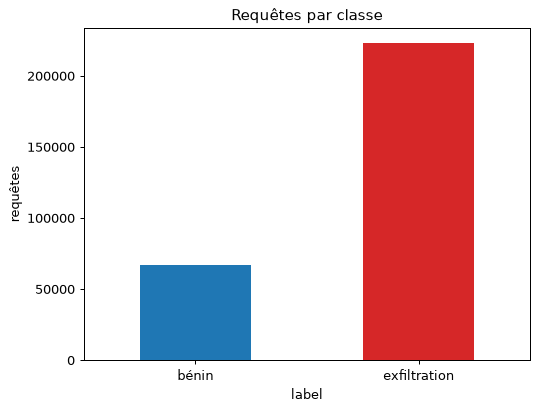

In [5]:
repartition = df["label"].map({0: "bénin", 1: "exfiltration"}).value_counts().sort_index()
print((repartition / len(df)).round(3))
repartition.plot.bar(title="Requêtes par classe", rot=0, color=["tab:blue", "tab:red"])
plt.ylabel("requêtes")
plt.show()

## 2. Un piège : les paquets tronqués

Les captures ont été enregistrées en ne gardant que les **96 premiers octets** de chaque paquet.
Il ne reste qu'une quarantaine de caractères du nom : **100 %** des noms d'exfiltration atteignent
40 caractères, contre **0,05 %** des noms bénins.

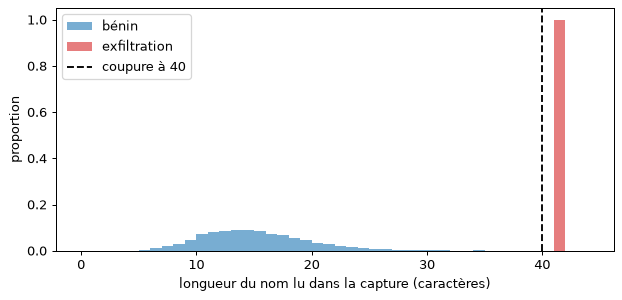

In [6]:
longueur = df["qname"].str.len()
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, nom, couleur in ((0, "bénin", "tab:blue"), (1, "exfiltration", "tab:red")):
    longueur[df["label"] == label].plot.hist(
        bins=range(0, 45), alpha=0.6, density=True, label=nom, color=couleur, ax=ax
    )
ax.axvline(LONGUEUR_MAX, color="black", linestyle="--", label=f"coupure à {LONGUEUR_MAX}")
ax.set_xlabel("longueur du nom lu dans la capture (caractères)")
ax.set_ylabel("proportion")
ax.legend()
plt.show()

Si on calculait les features sur les noms bruts, le modèle risquerait d'apprendre
« nom coupé = exfiltration », un artefact de la capture qui n'existe pas sur un vrai réseau.
**Parade** : toutes les features sont calculées sur les **40 premiers caractères**
du nom (`LONGUEUR_MAX`), à l'entraînement comme en production.

## 3. Les features retenues

L'article définit 14 features *stateless* (calculées sur une seule requête) et 16 *stateful*
(calculées sur une fenêtre de requêtes). On garde **9 features stateless**, celles qui ne dépendent
que des caractères du nom, pour pouvoir juger **chaque requête dès qu'elle passe** :

| Feature | Signification |
|---|---|
| `FQDN_count` | nombre de caractères du nom |
| `upper`, `lower`, `numeric`, `special` | nombre de majuscules, minuscules, chiffres, autres caractères |
| `entropy` | entropie de Shannon des caractères (désordre du texte) |
| `labels` | nombre de parties séparées par des points |
| `labels_max`, `labels_average` | longueur du plus long label, longueur moyenne |

Écartées : `sld`, `subdomain`, `subdomain_length`, `len`, qui supposent de connaître le suffixe
public (`.com`, `.co.uk`…), jamais visible dans les noms d'exfiltration tronqués ; `longest_word`,
qui demande un dictionnaire.

La même fonction `extract_features` sert à l'entraînement et à l'inférence :

In [7]:
benin = df.loc[df["label"] == 0, "qname"].iloc[0]
exfil = df.loc[df["label"] == 1, "qname"].iloc[0]
pd.DataFrame({benin: extract_features(benin), exfil: extract_features(exfil)}).round(2)

,dns.google,init.KNUGC2CNMFTWQ43POVSC43LQGN6DGOBQGY3Q
FQDN_count,10.00,40.0
upper,0.00,28.0
lower,9.00,4.0
numeric,0.00,7.0
special,1.00,1.0
entropy,2.92,4.5
labels,2.00,2.0
labels_max,6.00,35.0
labels_average,4.50,19.5


### Distribution des features par classe

Chaque barre donne la part des requêtes de la classe qui tombent dans l'intervalle.

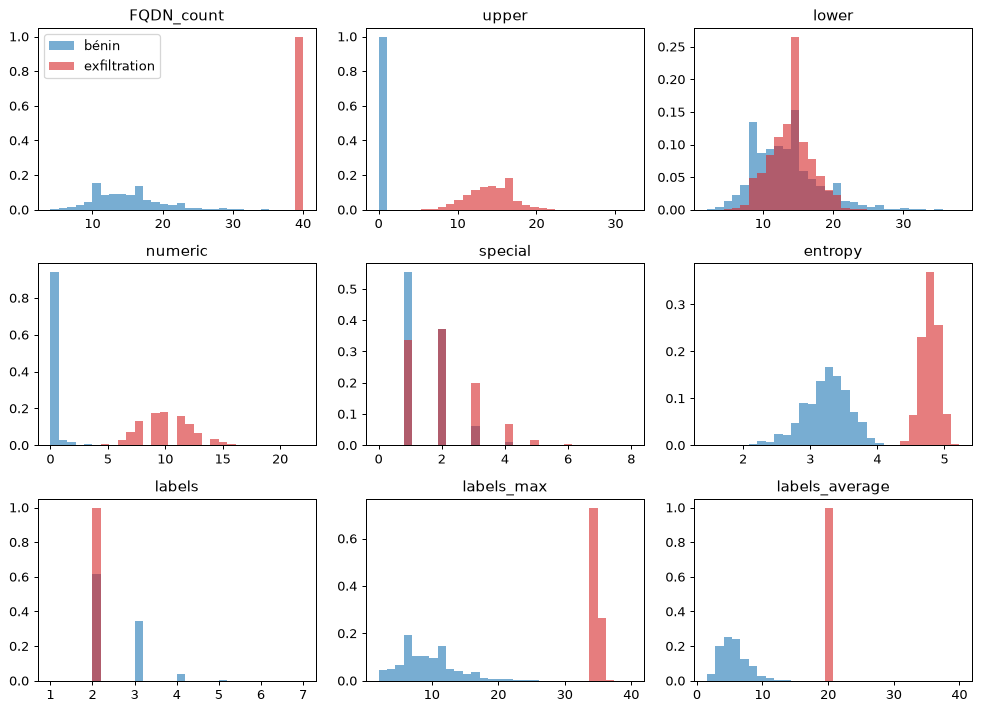

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8))
for feature, ax in zip(FEATURES, axes.ravel(), strict=True):
    intervalles = np.histogram_bin_edges(df[feature], bins=30)  # communs aux deux classes
    for label, nom, couleur in ((0, "bénin", "tab:blue"), (1, "exfiltration", "tab:red")):
        valeurs = df.loc[df["label"] == label, feature]
        poids = np.full(len(valeurs), 1 / len(valeurs))  # proportion de la classe
        ax.hist(valeurs, bins=intervalles, weights=poids, alpha=0.6, label=nom, color=couleur)
    ax.set_title(feature)
axes[0, 0].legend()
fig.tight_layout()
plt.show()

In [9]:
df.groupby("label")[FEATURES].median().rename(index={0: "bénin", 1: "exfiltration"}).round(2)

,FQDN_count,upper,lower,numeric,special,entropy,labels,labels_max,labels_average
label,,,,,,,,,
bénin,14.0,0.0,13.0,0.0,1.0,3.28,2.0,9.0,5.5
exfiltration,40.0,14.0,14.0,10.0,2.0,4.78,2.0,34.0,19.5


Les deux classes sont très séparées : les noms d'exfiltration sont longs, riches en majuscules
et en chiffres, à forte entropie, avec un très long label (les données encodées).
La tâche est donc **facile sur ce dataset**, et les scores seront très élevés : il faudra le dire
et vérifier le modèle sur du trafic réel.

Deux limites à garder en tête pour le déploiement :
- **aucun nom bénin ne contient de majuscule** (domaines populaires en minuscules), alors que le
  base64 en est plein : un outil qui encode en minuscules (hexadécimal, base32) n'aurait pas cet
  indice, et seuls la longueur, le très long label, les chiffres et l'entropie le trahiraient ;
- les noms bénins sont courts ; un vrai réseau a des noms longs et aléatoires légitimes
  (CDN, services cloud), source possible de faux positifs.

## 4. Découpage entraînement / test

Les requêtes d'une même capture se ressemblent énormément (même fichier exfiltré, même session de
navigation). Un tirage aléatoire 70/30, comme dans l'article, mettrait des quasi-doublons des deux
côtés et surestimerait les performances.

On met donc de côté des **captures entières** pour le test : `heavy_video` (une exfiltration
d'un type de fichier jamais vu à l'entraînement) et `benign_heavy_3` (une session de navigation
jamais vue).

In [10]:
train, test = split_par_capture(df, CAPTURES_TEST)
resume = pd.DataFrame(
    {
        "requêtes": [len(train), len(test)],
        "part du total": [len(train) / len(df), len(test) / len(df)],
        "part d'exfiltration": [train["label"].mean(), test["label"].mean()],
    },
    index=["entraînement", "test"],
).round(3)
resume

,requêtes,part du total,part d'exfiltration
entraînement,220037,0.758,0.809
test,70159,0.242,0.638


Environ 24 % des requêtes servent au test. La part d'exfiltration y est plus faible qu'à
l'entraînement (64 % contre 81 %) : c'est sans gravité, puisque les métriques retenues (rappel,
taux de faux positifs) se calculent classe par classe.
Le jeu de test n'est **jamais** utilisé pour choisir le modèle ni le seuil : il sert uniquement à
mesurer les performances finales (partie 2).

## 5. Modèle de référence : régression logistique

Avant le réseau de neurones, un modèle simple et lisible sert de point de comparaison : une
**régression logistique** (standardisation des features, puis combinaison linéaire passée dans une
sigmoïde). `class_weight="balanced"` compense le déséquilibre des classes. Si le réseau ne fait
pas mieux que ce modèle, sa complexité n'est pas justifiée.

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

from exfildns.evaluation import SEUIL, evaluer, importance_permutation
from exfildns.model import entrainer_mlp, entrainer_reference, predire_proba, sauvegarder

X_train, y_train = train[FEATURES], train["label"]
X_test, y_test = test[FEATURES], test["label"]

reference = entrainer_reference(X_train, y_train)

## 6. Réseau de neurones (TensorFlow / Keras)

Un petit perceptron multicouche, volontairement simple pour rester explicable :

```
9 features → Normalization → Dense 32 (ReLU) → Dense 16 (ReLU) → Dense 1 (sigmoïde) = probabilité
```

- **Normalization** : met chaque feature à l'échelle (moyenne 0, écart-type 1). Elle est adaptée sur
  le jeu d'entraînement **seulement** et enregistrée dans le fichier `.keras` : en production, la
  même mise à l'échelle est appliquée automatiquement.
- **Sortie sigmoïde** + perte **entropie croisée binaire**, optimiseur **adam** (comme en TP).
- **Validation** : 20 % du jeu d'entraînement. L'**arrêt anticipé** (`EarlyStopping`, patience 3)
  garde les poids de l'époque où la perte de validation est la plus basse, pour éviter le
  sur-apprentissage.
- **Graine fixée** (`keras.utils.set_random_seed(0)`) : résultats reproductibles.

In [12]:
reseau, historique = entrainer_mlp(X_train, y_train)
print(f"Arrêt après {len(historique['loss'])} époques")
reseau.summary()

Arrêt après 13 époques


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization (Normalization)   │ (None, 9)              │            19 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,616 (10.23 KB)

 Trainable params: 865 (3.38 KB)

 Non-trainable params: 19 (80.00 B)

 Optimizer params: 1,732 (6.77 KB)

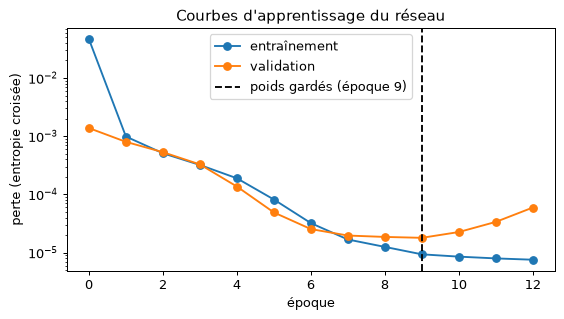

In [13]:
meilleure = int(np.argmin(historique["val_loss"]))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(historique["loss"], marker="o", label="entraînement")
ax.plot(historique["val_loss"], marker="o", label="validation")
ax.axvline(meilleure, color="black", linestyle="--", label=f"poids gardés (époque {meilleure})")
ax.set_xlabel("époque")
ax.set_ylabel("perte (entropie croisée)")
ax.set_yscale("log")
ax.set_title("Courbes d'apprentissage du réseau")
ax.legend()
plt.show()

Les deux pertes baissent ensemble, puis la perte de validation **remonte** alors que celle
d'entraînement continue de baisser : c'est le début du **sur-apprentissage** (le réseau apprend
des détails du jeu d'entraînement qui ne se généralisent pas). L'arrêt anticipé stoppe
l'entraînement 3 époques après le minimum et **restaure les poids de l'époque où la perte de
validation est la plus basse** (ligne pointillée).

## 7. Choix de la métrique et performances

Classe positive : l'**exfiltration**.

| Métrique | Formule | Question |
|---|---|---|
| **Rappel** (principale) | VP / (VP + FN) | Quelle part des exfiltrations détecte-t-on ? |
| **Taux de faux positifs** | FP / (FP + VN) | Quelle part du trafic normal déclenche une alerte ? |
| Précision | VP / (VP + FP) | Quelle part des alertes est justifiée ? |
| PR-AUC | aire sous la courbe précision-rappel | Qualité du classement, quel que soit le seuil |

- **Rater une exfiltration** est le pire cas : les données sortent sans alerte → le **rappel**
  est la métrique principale.
- Un détecteur qui alerte sur tout a 100 % de rappel et ne sert à rien : sur un vrai réseau, le DNS
  bénin est massif, chaque point de **taux de faux positifs** fait des milliers d'alertes inutiles.
- L'**accuracy** est écartée : elle dépend de la proportion des classes, inversée ici par rapport
  à la réalité.

**Seuil de décision : 0,5**, celui par défaut d'une sortie sigmoïde. Il n'est **pas** réglé en
regardant le jeu de test, ce qui serait une fuite.

In [14]:
# une ligne par modèle : chaque colonne garde son type (taux ou nombre de requêtes)
resultats = pd.DataFrame.from_dict(
    {
        "régression logistique": evaluer(reference, X_test, y_test),
        "réseau de neurones": evaluer(reseau, X_test, y_test),
    },
    orient="index",
)
resultats.round(6)

,rappel,precision,f1,pr_auc,taux_faux_positifs,vrais_positifs,faux_positifs,faux_negatifs,vrais_negatifs
régression logistique,1.0,1.000000,1.000000,1.0,0.000000,44780,0,0,25379
réseau de neurones,1.0,0.999978,0.999989,1.0,0.000039,44780,1,0,25378


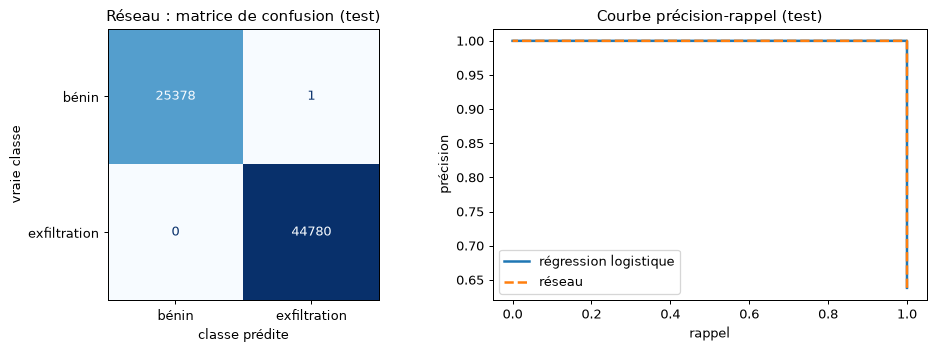

In [15]:
proba_reseau = predire_proba(reseau, X_test)
proba_reference = predire_proba(reference, X_test)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    (proba_reseau >= SEUIL).astype(int),
    display_labels=["bénin", "exfiltration"],
    cmap="Blues",
    values_format="d",
    colorbar=False,
    ax=axes[0],
)
axes[0].set_title("Réseau : matrice de confusion (test)")
axes[0].set_xlabel("classe prédite")
axes[0].set_ylabel("vraie classe")
for proba, nom, style in (
    (proba_reference, "régression logistique", "-"),
    (proba_reseau, "réseau", "--"),
):
    precision, rappel, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rappel, precision, style, linewidth=2, label=nom)
axes[1].set_xlabel("rappel")
axes[1].set_ylabel("précision")
axes[1].set_title("Courbe précision-rappel (test)")
axes[1].legend()
fig.tight_layout()
plt.show()

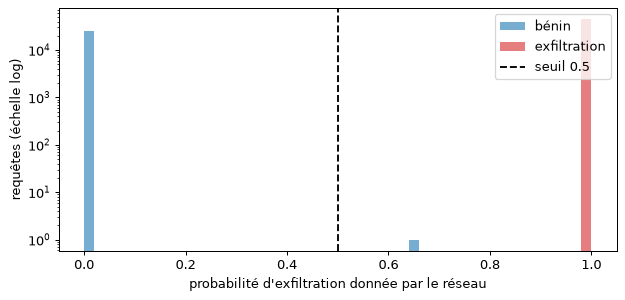

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, nom, couleur in ((0, "bénin", "tab:blue"), (1, "exfiltration", "tab:red")):
    probas = proba_reseau[y_test == label]
    ax.hist(probas, bins=50, range=(0, 1), alpha=0.6, label=nom, color=couleur)
ax.axvline(SEUIL, color="black", linestyle="--", label=f"seuil {SEUIL}")
ax.set_yscale("log")
ax.set_xlabel("probabilité d'exfiltration donnée par le réseau")
ax.set_ylabel("requêtes (échelle log)")
ax.legend()
plt.show()

Les deux modèles sont quasi parfaits sur des captures jamais vues (leurs courbes
précision-rappel se superposent), et les probabilités sont très tranchées : presque toutes proches
de 0 ou de 1. Une seule requête bénigne dépasse le seuil. **La régression logistique fait aussi bien que le réseau** :
sur ce dataset, le réseau n'apporte rien. On le garde parce qu'il est demandé et parce qu'il peut
capter des combinaisons non linéaires sur des données plus difficiles (trafic réel).

## 8. Explicabilité : quelles features comptent ?

**Importance par permutation** : on mélange les valeurs d'une feature entre les requêtes du test,
ce qui casse son lien avec l'étiquette, puis on mesure la hausse de la perte. Plus la hausse est
forte, plus le modèle s'appuie sur cette feature. La méthode marche pour n'importe quel modèle,
réseau compris.

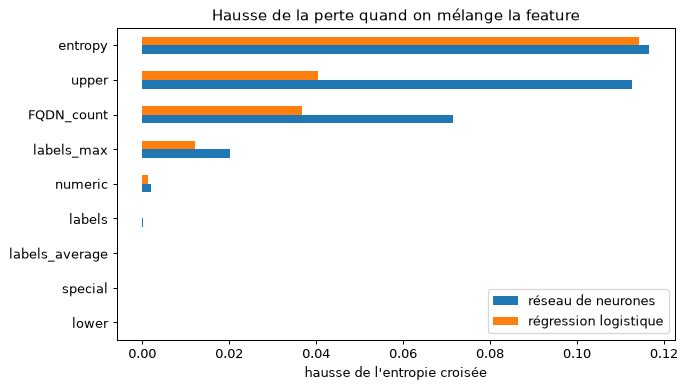

,réseau de neurones,régression logistique
entropy,0.117,0.114
upper,0.113,0.040
FQDN_count,0.071,0.037
labels_max,0.020,0.012
numeric,0.002,0.001
labels,0.000,-0.000
labels_average,0.000,-0.000
special,0.000,0.000
lower,0.000,-0.000


In [17]:
importances = pd.DataFrame(
    {
        "réseau de neurones": importance_permutation(reseau, X_test, y_test),
        "régression logistique": importance_permutation(reference, X_test, y_test),
    }
).sort_values("réseau de neurones")
importances.plot.barh(figsize=(8, 4.5), title="Hausse de la perte quand on mélange la feature")
plt.xlabel("hausse de l'entropie croisée")
plt.show()
importances.sort_values("réseau de neurones", ascending=False).round(3)

Les deux modèles s'appuient sur les **mêmes signaux** : l'entropie (caractères aléatoires),
les majuscules, la longueur du nom et celle du plus long label, c'est-à-dire la signature d'un
encodage base64 dans un sous-domaine.

> *Le réseau signale une requête quand son nom est long, aléatoire, contient des majuscules et un
> label très long : quand il ressemble à des données encodées plutôt qu'à un nom choisi par un
> humain.*

### Le dataset est-il trop facile ?

Test simple : une régression logistique avec **une seule feature**.

In [18]:
une_feature = {}
for feature in FEATURES:
    modele = entrainer_reference(X_train[[feature]], y_train)
    m = evaluer(modele, X_test[[feature]], y_test)
    une_feature[feature] = {"rappel": m["rappel"], "taux_faux_positifs": m["taux_faux_positifs"]}
pd.DataFrame(une_feature).T.sort_values("taux_faux_positifs").round(4)

,rappel,taux_faux_positifs
upper,0.9999,0.0000
entropy,0.9999,0.0000
labels_max,1.0000,0.0005
labels_average,1.0000,0.0006
FQDN_count,1.0000,0.0008
numeric,0.9990,0.0015
special,0.6636,0.4175
lower,0.5498,0.4320
labels,1.0000,0.6284


Plusieurs features suffisent presque à elles seules : le dataset est **trop facile**
(base64 de DNSExfiltrator contre domaines populaires). Les très bons scores ne garantissent donc
pas les performances sur un vrai réseau, d'où la validation en conditions réelles prévue pour le
déploiement :

1. **trafic bénin peu réaliste** (top Alexa) : les noms longs et aléatoires légitimes (CDN, cloud)
   risquent de provoquer des faux positifs ;
2. **un seul outil d'attaque** : un outil qui encode en minuscules (hexadécimal, base32) ou
   raccourcit ses labels réduit les écarts sur `upper`, `entropy` et `FQDN_count` ;
3. **analyse requête par requête** : ni le volume ni le rythme des requêtes vers un même domaine ne
   sont vus par le modèle. L'application compense en agrégeant les alertes par domaine parent.

## 9. Sauvegarde du modèle pour l'application

Le réseau (normalisation comprise) est enregistré dans un seul fichier `.keras`, chargé par
l'application de détection (`exfildns scan`, `exfildns sniff`, dashboard). C'est le même modèle
que celui produit par `exfildns train`.

In [19]:
sauvegarder(reseau, "../models/exfildns.keras")
print("Modèle sauvegardé : models/exfildns.keras")

Modèle sauvegardé : models/exfildns.keras
